# 텍스트 RAG

In [1]:
import os

from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from dotenv import load_dotenv

load_dotenv()

# 답변용 LLM
llm = ChatOpenAI(model="gpt-4o-mini",temperature=0)

# 검색용 임베딩 모델
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

print("LLM + 임베딩 준비 완료")

LLM + 임베딩 준비 완료


### 필요한 모듈 설치

In [7]:
import re
from langchain_community.document_loaders import PyPDFLoader
from langchain_chroma import Chroma
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough


docs = PyPDFLoader("../data/assignment.pdf").load()
print(len(docs))
print(docs[3].page_content)
print("PDF 로드 완료")

20
3분기 주요 메시지
역대 최대 3분기 매출액 기록
관세 영향 본격화와 이로 인한 수요 둔화 우려 불구,
판매 호조세로 역대 3분기 기준 최대 매출액 기록
3
미국 시장 지배력 강화
다변화된 PT전략 기반 소비자 공략
소매 상승세 지속으로 3분기 M/S 6.3% 기록
6.3% 21%47조원
고수익 차종 판매비중 확대 지속
HEV·제네시스 합산 판매 비중 21% 기록으로
2개 분기 연속 비중 20% 이상 달성
PDF 로드 완료


### pdf 간지 페이지 제거

In [5]:
docs = [d for d in docs if len(d.page_content.strip()) >= 80]
print(len(docs))

13


### 정규식 정제

In [8]:
RULES = [
    (r"^\s*\d{1,2}\s*$", ""),                       # 단독 페이지 번호 줄
    (r"(?<=[가-힣])[1-7](?=\s|$)", ""),              # 각주: 미국2, 중국5, 판매7
    (r"Q([1-4])\s*(20\d{2})", r"\2년 \1분기"),       # Q3 2025 → 2025년 3분기
    (r"[’'](\d{2})\.(\d)분기", r"20\1년 \2분기"),    # ’25.3분기 → 2025년 3분기
]

def clean(t):
    for p, r in RULES:
        t = re.sub(p, r, t, flags=re.M)
    return t

target = next(d for d in docs if d.metadata["page"] == 5)
before = target.page_content    # 원본 저장

for d in docs:                  # 전체 적용
    d.page_content = clean(d.page_content)

print("=========적용전\n", before[:600])
print("=========적용후\n", target.page_content[:600])

=========적용전
 (단위 : 천대)
Q3 2024 도매 Q3 2025 도매
글로벌 판매7
Q3 2024 소매 Q3 2025 소매
아태
54 44 52 45
-12.3%-18.6%
1 미국, 유럽, 국내 : 소매 기준, 인도 : 도매 기준
2 북미 판매량 ’25.3분기 도매 315천대 / 소매 315천대
3 소형, 대형 상용 포함
4 인도 내수 판매, 인도권 대리점 미포함
5 중국 상용, 제네시스 포함
6 러시아, 기타 권역
7 상용포함
5
글로벌 도·소매판매 현황
Q3 2024 산업수요1 Q3 2025 산업수요1
중남미
82 83 80 83
+3.2%+1.0%
미국2
3,908 4,155
251 257 231 261
+12.7%+2.4%
+6.3%
3,641 3,781
139 150 145 150
유럽
+8.3% +3.2%
+3.8%
인도4
1,065
1,061
150 140 140 136
-6.8% -2.8%
-0.4%
5,584 6,069
22 32 31 29
중국5
+48.7% -4.1%
+8.7%
국내3
393 437
170 181 170 181
+6.3% +6.3%
+11.2%
20,581 21,397
1,012 1,038 989 1,036 
+4.8%+2.6%
+4
=========적용후
 (단위 : 천대)
2024년 3분기 도매 2025년 3분기 도매
글로벌 판매
2024년 3분기 소매 2025년 3분기 소매
아태
54 44 52 45
-12.3%-18.6%
1 미국, 유럽, 국내 : 소매 기준, 인도 : 도매 기준
2 북미 판매량 2025년 3분기 도매 315천대 / 소매 315천대
3 소형, 대형 상용 포함
4 인도 내수 판매, 인도권 대리점 미포함
5 중국 상용, 제네시스 포함
6 러시아, 기타 권역
7 상용포함

글로벌 도·소매판매 현황
2024년 3분기 산업수요 2025년 3분기 산업수요
중남미
82 83 80 83
+3.2%+1.0%
미국
3,908 4,155
251 257 231 261
+12.7%+2.4%
+6.3%
3,641

### 벡터 저장소 + 리트리버 + 체인

In [14]:
vectorstore = Chroma.from_documents(docs, embeddings, collection_name="text_rag")
retriever = vectorstore.as_retriever(search_kwargs={"k": 4})

prompt = ChatPromptTemplate.from_template(
    "아래 문맥만 사용해 답하라. 문맥에 없으면 '자료에서 확인 불가'라고 답하라.\n"
    "숫자에는 단위(십억원, 천대, %)를 붙이고, 근거 페이지를 함께 적어라.\n\n"
    "문맥:\n{context}\n\n질문: {question}"
)

def format_docs(ds):
    return "\n\n".join(f"[p.{d.metadata['page']}]\n{d.page_content}" for d in ds)

text_rag_chain = (
    {"context": retriever | format_docs, "question": RunnablePassthrough()}
    | prompt | llm | StrOutputParser()
)


### 텍스트 RAG 평가 질문

In [15]:
questions = [
    "3분기 매출액은?",                         
    "영업이익의 전년 대비 증감률은?",          
    "자동차 부문 영업이익은?",            
    "미국 HEV 판매 비중은?",             
    "유럽 도매 판매 증감률은?",             
]

for q in questions:
    print("질문:", q)
    print("답변:", text_rag_chain.invoke(q), "\n")

질문: 3분기 매출액은?
답변: 자료에서 확인 불가 

질문: 영업이익의 전년 대비 증감률은?
답변: 자료에서 확인 불가. 

질문: 자동차 부문 영업이익은?
답변: 자동차 부문 영업이익은 2025년 3분기에 1,174 십억원입니다. (p.11) 

질문: 미국 HEV 판매 비중은?
답변: 미국 HEV 판매 비중은 20.4%입니다. (p.6) 

질문: 유럽 도매 판매 증감률은?
답변: 자료에서 확인 불가. 



## 멀티모달 RAG

In [2]:
import shutil
import sys

print("Python:", sys.version.split()[0])
print("가상환경 경로:", sys.prefix)
print("가상환경 안에서 실행 중?", ".venv" in sys.prefix)
print()

# OS 패키지 확인 (pip로 설치되지 않는 것들)
print("Poppler  :", "OK" if shutil.which("pdftoppm") else "✗ 미설치 — Path 확인 후 재시작")
print("Tesseract:", "OK" if shutil.which("tesseract") else "✗ 미설치 — Path 확인 후 재시작")
print()

# 파이썬 패키지 확인
for mod in ["langchain", "unstructured", "chromadb", "tiktoken", "PIL"]:
    try:
        __import__(mod)
        print(f"{mod:14s}: OK")
    except ImportError:
        print(f"{mod:14s}: ✗ 미설치")

Python: 3.11.9
가상환경 경로: c:\workspace\multimodal-rag\.venv
가상환경 안에서 실행 중? True

Poppler  : OK
Tesseract: OK

langchain     : OK
unstructured  : OK
chromadb      : OK
tiktoken      : OK
PIL           : OK


In [32]:
# PDF에서 표, 텍스트, 이미지 같은 요소를 추출하기 위해 사용되는 기능
import os
from pathlib import Path

from langchain_text_splitters import CharacterTextSplitter
from unstructured.partition.pdf import partition_pdf

def extract_pdf_elements(path, fname): # PDF에서 elements를 추출하는 함수
    """
    PDF 파일에서 이미지, 테이블, 텍스트 블록을 추출합니다.
    path: 파일 경로 (추출된 이미지 파일이 저장될 위치)
    fname: 파일 이름
    """
    return partition_pdf( # unstructured가 주는 함수
        filename=path + fname,
        strategy="hi_res",              # 레이아웃 분석 모델로 정밀 추출
        extract_images_in_pdf=True,     # PDF에서 이미지를 추출
        infer_table_structure=True,     # 테이블 구조를 추론
        chunking_strategy="by_title",   # 타이틀을 기준으로 텍스트를 블록으로 분할
        max_characters=4000,            # 최대 4000자로 텍스트 블록을 제한
        new_after_n_chars=3000,         # 3000자 이후에 새로운 블록 생성
        combine_text_under_n_chars=2000, # 2000자 이하의 텍스트는 결합
        extract_image_block_output_dir=path+"/project",     # 이미지가 저장될 경로 설정
    )

print("extract_pdf_elements 정의 완료")

extract_pdf_elements 정의 완료


In [33]:
def categorize_elements(raw_pdf_elements): # elements를 분류
    """
    PDF에서 추출한 요소들을 테이블과 텍스트로 분류합니다.
    raw_pdf_elements: unstructured.documents.elements 리스트
    """
    tables = []
    texts = []
    for element in raw_pdf_elements:
        if "unstructured.documents.elements.Table" in str(type(element)):
            tables.append(str(element))     # 테이블 요소를 저장
        elif "unstructured.documents.elements.CompositeElement" in str(type(element)):
            texts.append(str(element))      # 텍스트 요소를 저장
    return texts, tables

print("categorize_elements 정의 완료")

categorize_elements 정의 완료


In [34]:
import os

# 현재 작업 디렉터리 경로를 반환합니다.
current_directory = os.getcwd()

# fname: 처리할 PDF 파일 이름 / fpath: PDF가 저장된 폴더 경로
fname = "assignment.pdf"
fpath = os.path.join(os.path.dirname(current_directory), "data/" )

# 실행하면 2~3분 걸린다. 멈춘게 아니니 기다리세요.
print("현재 스크립트의 위치:", current_directory)
print("pdf 위치:", fpath)

현재 스크립트의 위치: c:\workspace\multimodal-rag\notebooks
pdf 위치: c:\workspace\multimodal-rag\data/


### 추출 실행

In [35]:
import time

start = time.time()

raw_pdf_elements = extract_pdf_elements(fpath, fname)

print(f"추출 완료 - {time.time() - start:.1f} 초 소요")
print("추출 된 요소 수", len(raw_pdf_elements))

No languages specified, defaulting to English.


추출 완료 - 125.1 초 소요
추출 된 요소 수 19


In [37]:
texts, tables = categorize_elements(raw_pdf_elements)

print("텍스트 블록 수:", len(texts))
print("표 블록 수:", len(tables))

텍스트 블록 수: 10
표 블록 수: 9


## 어떤 요소들이 나왔는지 집계

In [38]:
from collections import Counter

type_counts = Counter(str(type(el)).split(".")[-1].strip("'>") for el in raw_pdf_elements)

for element_type, count in type_counts.most_common():
    print(f"{element_type:22s}: {count}개")

CompositeElement      : 10개
Table                 : 9개


## 추출된 이미지 확인

In [39]:
project_dir = Path(fpath) / "project"

if project_dir.exists():
    image_files = sorted(
        p for p in project_dir.iterdir()
        if p.suffix.lower() in (".jpg", ".jpeg", ".png")
    )
    print(f"추출된 이미지: {len(image_files)}개\n")
    for p in image_files[:10]:
        print(f"    {p.name}  ({p.stat().st_size // 1024} KB)")
else:
    print("project 폴더가 없습니다")

추출된 이미지: 19개

    figure-1-1.jpg  (269 KB)
    figure-10-17.jpg  (51 KB)
    figure-14-18.jpg  (45 KB)
    figure-14-19.jpg  (43 KB)
    figure-3-2.jpg  (4 KB)
    figure-4-3.jpg  (10 KB)
    figure-4-4.jpg  (8 KB)
    figure-6-10.jpg  (39 KB)
    figure-6-5.jpg  (18 KB)
    figure-6-6.jpg  (19 KB)


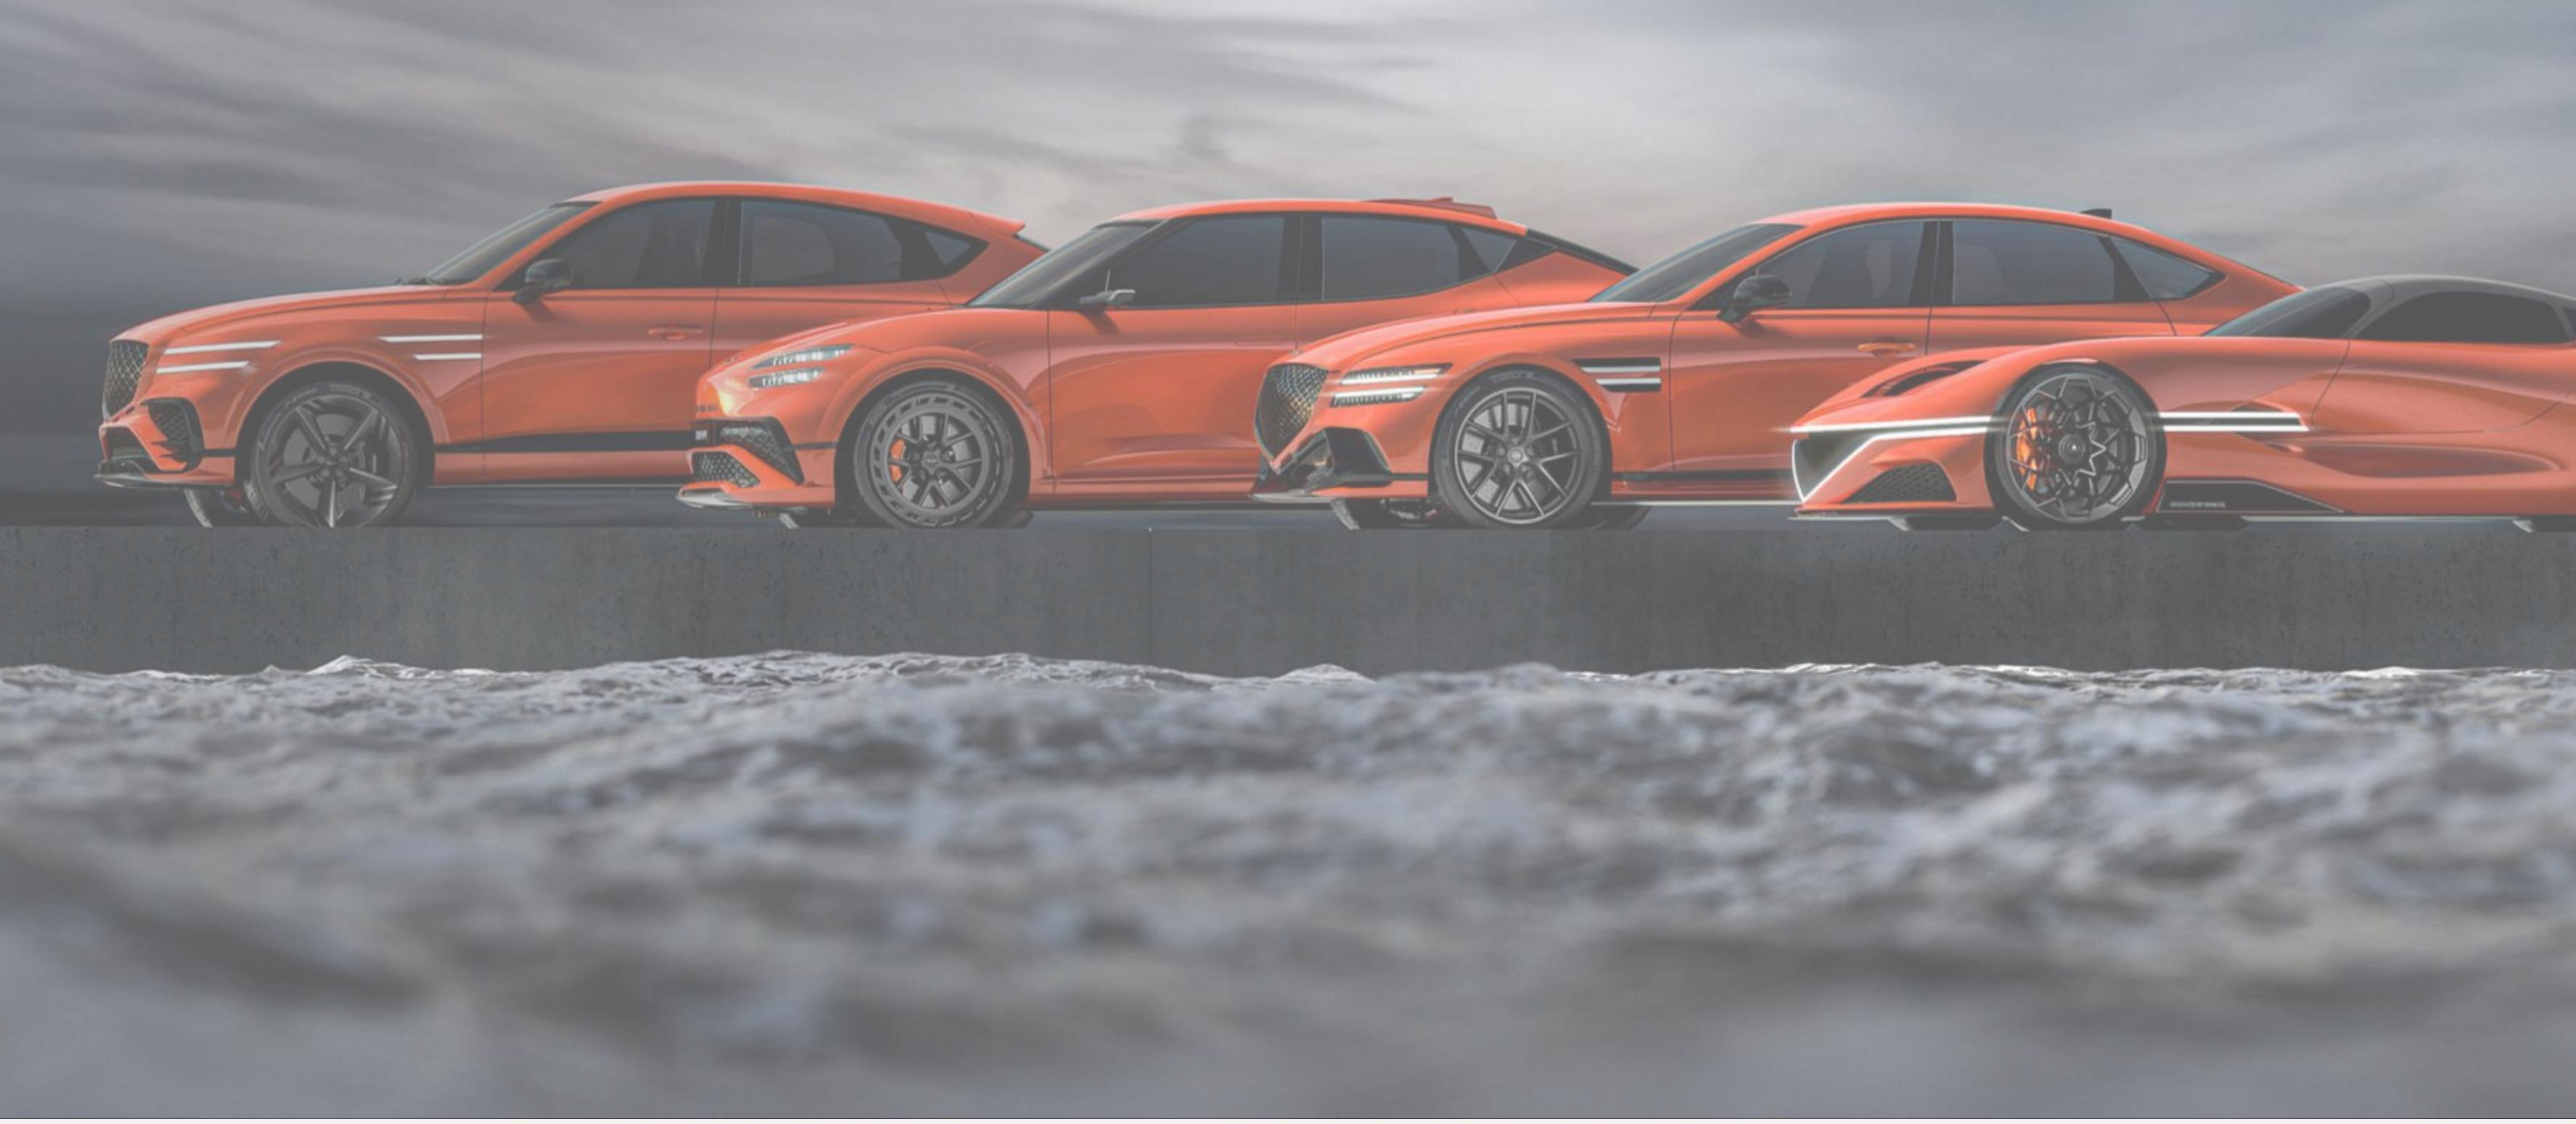

In [40]:
from IPython.display import Image, display

if project_dir.exists() and image_files:
    display(Image(filename=str(image_files[0]), width=500))
else:
    print("표시할 이미지가 없습니다.")